# ARX specification selection

Compare autoregressive NPL models containing both oil and FX, using pre-2022 training data only. Notebook 3's NPL-only comparisons remain unchanged; this notebook does not perform validation, forecasting or a stress scenario.

Run from `notebooks/`. Input: `data/processed/train.csv`, saved by Notebook 3.

## Imports and configuration

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

TRAIN_DATA_PATH = Path("../data/processed/train.csv")
DIAGNOSTIC_DIRECTORY = Path("../reports/diagnostics")
EXPECTED_COLUMNS = ["quarter", "npl", "brent", "usdkzt"]
VALUE_COLUMNS = EXPECTED_COLUMNS[1:]
TRAIN_END = pd.Period("2021Q4", freq="Q-DEC")
TARGET_COLUMN = "npl_change_pp"
NPL_LAGS = [1, 2]
MACRO_LAGS = [1, 2, 3, 4]
MAX_FEATURE_LAG = max(NPL_LAGS + MACRO_LAGS)
RESIDUAL_PLOT_LAG = 8
BG_TEST_LAG = 4
SHORTLIST_DELTA_AICC = 2.0

assert TRAIN_DATA_PATH.exists(), "Run Notebook 3 to save the training dataset."

## Training data and checks

Load only the saved 48 training quarters. The 2022+ evaluation pool is not loaded or used for specification selection here.

In [2]:
training_snapshot = pd.read_csv(TRAIN_DATA_PATH)
display(training_snapshot.head())
training_snapshot.info()

assert training_snapshot.columns.tolist() == EXPECTED_COLUMNS
assert training_snapshot["quarter"].str.fullmatch(r"\d{4}Q[1-4]").all()
assert training_snapshot[VALUE_COLUMNS].select_dtypes(include=np.number).shape[1] == 3
assert not training_snapshot.isna().any().any()
assert np.isfinite(training_snapshot[VALUE_COLUMNS].to_numpy()).all()
assert training_snapshot["npl"].between(0, 100).all()
assert training_snapshot[["brent", "usdkzt"]].gt(0).all().all()

quarter_index = pd.PeriodIndex(training_snapshot["quarter"], freq="Q-DEC")
expected_quarters = pd.period_range("2010Q1", TRAIN_END, freq="Q-DEC")
assert quarter_index.equals(expected_quarters)
assert quarter_index.is_unique and len(quarter_index) == 48

train_data = training_snapshot[VALUE_COLUMNS].copy()
train_data.index = quarter_index
train_data.index.name = "quarter"

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   quarter  48 non-null     object 
 1   npl      48 non-null     float64
 2   brent    48 non-null     float64
 3   usdkzt   48 non-null     float64
dtypes: float64(3), object(1)
memory usage: 1.6+ KB


,quarter,npl,brent,usdkzt
0,2010Q1,24.9600,76.6700,147.7000
1,2010Q2,25.2500,78.8500,146.8100
2,2010Q3,25.8300,76.6800,147.4100
3,2010Q4,23.7500,87.0300,147.4900
4,2011Q1,25.2700,105.3700,146.4200


## Transformations and predictor timing

Reuse the transformations from Notebooks 2–3: NPL first differences in percentage points, and oil/FX changes as 100 × log differences. Positive FX changes mean tenge depreciation.

A row targets quarter $t$. Every predictor comes from $t-1$ or earlier; there are no contemporaneous macro predictors. Genuine jumps are retained.

In [3]:
# calculate deterministic changes without rounding model inputs
training_changes = pd.DataFrame({
    TARGET_COLUMN: train_data["npl"].diff(),
    "brent_log_change_pct": np.log(train_data["brent"]).diff() * 100,
    "usdkzt_log_change_pct": np.log(train_data["usdkzt"]).diff() * 100,
}, index=train_data.index)

assert training_changes.iloc[0].isna().all()
assert training_changes.iloc[1:].notna().all().all()
assert np.isfinite(training_changes.iloc[1:].to_numpy()).all()
display(training_changes.head())

# shift before removing initial missing rows to preserve quarterly timing
training_features = training_changes[[TARGET_COLUMN]].copy()
for column in training_changes.columns:
    for lag in range(1, MAX_FEATURE_LAG + 1):
        feature = f"{column}_lag_{lag}"
        training_features[feature] = training_changes[column].shift(lag)

model_data = training_features.dropna().copy()
assert model_data.index.equals(train_data.index[MAX_FEATURE_LAG + 1:])
assert len(model_data) == 43
assert model_data.index.min() == pd.Period("2011Q2", freq="Q-DEC")
assert model_data.index.max() == TRAIN_END
assert np.isfinite(model_data.to_numpy()).all()

# verify lag values against their exact source quarters
for column in training_changes.columns:
    for lag in range(1, MAX_FEATURE_LAG + 1):
        source_quarters = model_data.index - lag
        expected_values = training_changes.loc[source_quarters, column].set_axis(
            model_data.index
        )
        pd.testing.assert_series_equal(
            model_data[f"{column}_lag_{lag}"], expected_values,
            check_names=False, check_exact=True,
        )
        assert (source_quarters < model_data.index).all()

display(pd.DataFrame({
    "first_target_quarter": [str(model_data.index.min())],
    "last_target_quarter": [str(model_data.index.max())],
    "observations": [len(model_data)],
}))
display(model_data.head())

,npl_change_pp,brent_log_change_pct,usdkzt_log_change_pct
quarter,,,
2010Q1,NaN,NaN,NaN
2010Q2,0.2900,2.8037,-0.6044
2010Q3,0.5800,-2.7906,0.4079
2010Q4,-2.0800,12.6612,0.0543
2011Q1,1.5200,19.1225,-0.7281


,first_target_quarter,last_target_quarter,observations
0,2011Q2,2021Q4,43


,npl_change_pp,npl_change_pp_lag_1,npl_change_pp_lag_2,npl_change_pp_lag_3,npl_change_pp_lag_4,brent_log_change_pct_lag_1,brent_log_change_pct_lag_2,brent_log_change_pct_lag_3,brent_log_change_pct_lag_4,usdkzt_log_change_pct_lag_1,usdkzt_log_change_pct_lag_2,usdkzt_log_change_pct_lag_3,usdkzt_log_change_pct_lag_4
quarter,,,,,,,,,,,,,
2011Q2,1.0000,1.5200,-2.0800,0.5800,0.2900,19.1225,12.6612,-2.7906,2.8037,-0.7281,0.0543,0.4079,-0.6044
2011Q3,3.1900,1.0000,1.5200,-2.0800,0.5800,10.9301,19.1225,12.6612,-2.7906,-0.5685,-0.7281,0.0543,0.4079
2011Q4,1.1400,3.1900,1.0000,1.5200,-2.0800,-3.7004,10.9301,19.1225,12.6612,0.6640,-0.5685,-0.7281,0.0543
2012Q1,1.3000,1.1400,3.1900,1.0000,1.5200,-2.9476,-3.7004,10.9301,19.1225,0.9169,0.6640,-0.5685,-0.7281
2012Q2,-1.0000,1.3000,1.1400,3.1900,1.0000,7.4024,-2.9476,-3.7004,10.9301,0.1554,0.9169,0.6640,-0.5685


## Candidate specifications

Keep NPL-change lags 1–2 fixed initially. Cross one oil-change lag with one FX-change lag, each chosen from 1–4: **16 candidates**, with an intercept and four predictors each. Different oil and FX lags are allowed.

This is a restricted ARX search, not every possible distributed-lag model. Each macro variable enters at one selected lag. There are no MA terms; lag choices are not selected from individual coefficient p-values.

In [4]:
candidate_specifications = []

# include both macro variables in every candidate
npl_predictors = [f"{TARGET_COLUMN}_lag_{lag}" for lag in NPL_LAGS]
for oil_lag in MACRO_LAGS:
    for fx_lag in MACRO_LAGS:
        candidate_specifications.append({
            "model": f"ARX2_oil{oil_lag}_fx{fx_lag}",
            "oil_lag": oil_lag,
            "fx_lag": fx_lag,
            "predictors": npl_predictors + [
                f"brent_log_change_pct_lag_{oil_lag}",
                f"usdkzt_log_change_pct_lag_{fx_lag}",
            ],
        })

assert len(candidate_specifications) == len(MACRO_LAGS) ** 2 == 16
assert len({item["model"] for item in candidate_specifications}) == 16
assert all(len(item["predictors"]) == 4 for item in candidate_specifications)
display(pd.DataFrame([
    {key: value for key, value in item.items() if key != "predictors"}
    for item in candidate_specifications
]).set_index("model"))

,oil_lag,fx_lag
model,,
ARX2_oil1_fx1,1,1
ARX2_oil1_fx2,1,2
ARX2_oil1_fx3,1,3
ARX2_oil1_fx4,1,4
ARX2_oil2_fx1,2,1
ARX2_oil2_fx2,2,2
ARX2_oil2_fx3,2,3
ARX2_oil2_fx4,2,4
ARX2_oil3_fx1,3,1


## Training fit comparison

Estimate each specification with OLS on the same 43 rows. Compute Gaussian AIC/AICc/BIC with the five regression coefficients **plus the error-variance parameter** ($k=6$). All candidates have the same parameter count, so these criteria give the same ranking here.

These are training fit criteria, not backtest scores. Do not compare them directly with Notebook 3's 47-observation ARIMA criteria.

In [5]:
arx_results = {}
candidate_rows = []
y_train = model_data[TARGET_COLUMN].copy()

# fit each lag pair on an identical target sample
for specification in candidate_specifications:
    model_name = specification["model"]
    X_train = sm.add_constant(
        model_data[specification["predictors"]], has_constant="add"
    )
    assert X_train.index.equals(y_train.index)
    assert X_train.shape == (43, 5)
    assert np.linalg.matrix_rank(X_train.to_numpy()) == X_train.shape[1]

    result = sm.OLS(y_train, X_train, missing="raise").fit()
    assert int(result.nobs) == len(model_data)
    assert np.isfinite(result.params.to_numpy()).all()
    arx_results[model_name] = result

    observation_count = int(result.nobs)
    parameter_count = len(result.params) + 1
    assert observation_count > parameter_count + 1
    aic = -2 * result.llf + 2 * parameter_count
    aicc = aic + (
        2 * parameter_count * (parameter_count + 1)
        / (observation_count - parameter_count - 1)
    )
    bic = -2 * result.llf + parameter_count * np.log(observation_count)
    candidate_rows.append({
        "model": model_name,
        "oil_lag": specification["oil_lag"],
        "fx_lag": specification["fx_lag"],
        "observations": observation_count,
        "parameters_including_variance": parameter_count,
        "aic": aic,
        "aicc": aicc,
        "bic": bic,
        "adjusted_r_squared": result.rsquared_adj,
    })

arx_fit_comparison = pd.DataFrame(candidate_rows).set_index("model").sort_values(
    "aicc"
)
arx_fit_comparison["delta_aicc"] = (
    arx_fit_comparison["aicc"] - arx_fit_comparison["aicc"].min()
)
assert len(arx_results) == len(arx_fit_comparison) == 16
assert np.isfinite(arx_fit_comparison.to_numpy()).all()
display(arx_fit_comparison)

,oil_lag,fx_lag,observations,parameters_including_variance,aic,aicc,bic,adjusted_r_squared,delta_aicc
model,,,,,,,,,
ARX2_oil2_fx4,2,4,43,6,203.6363,205.9696,214.2035,0.1536,0.0000
ARX2_oil2_fx2,2,2,43,6,204.2836,206.6169,214.8508,0.1407,0.6473
ARX2_oil2_fx1,2,1,43,6,204.8002,207.1335,215.3674,0.1304,1.1639
ARX2_oil2_fx3,2,3,43,6,205.0519,207.3852,215.6191,0.1253,1.4156
ARX2_oil1_fx4,1,4,43,6,207.1596,209.4929,217.7268,0.0813,3.5233
ARX2_oil1_fx1,1,1,43,6,207.8879,210.2212,218.4551,0.0656,4.2516
ARX2_oil1_fx3,1,3,43,6,208.1674,210.5007,218.7346,0.0595,4.5311
ARX2_oil1_fx2,1,2,43,6,208.2263,210.5596,218.7935,0.0582,4.5900
ARX2_oil4_fx4,4,4,43,6,208.8302,211.1635,219.3974,0.0449,5.1939


## Multicollinearity and residual dependence

Calculate VIF on each actual predictor matrix, including the intercept in the calculation but not in the displayed VIF maximum. Use [Breusch–Godfrey](https://www.statsmodels.org/v0.14.0/generated/statsmodels.stats.diagnostic.acorr_breusch_godfrey.html) through lag 4 to check residual serial correlation in the dynamic regression, conditional on its regressors.

A large test p-value is not proof of white noise. These checks have limited power in a small sample and do not establish stability across regimes.

In [6]:
vif_rows = []
diagnostic_rows = []

# assess each fitted predictor matrix and its residuals
for model_name, result in arx_results.items():
    design_matrix = result.model.exog
    predictor_vifs = []
    for column_index, predictor in enumerate(result.model.exog_names):
        if predictor == "const":
            continue
        vif_value = variance_inflation_factor(design_matrix, column_index)
        predictor_vifs.append(vif_value)
        vif_rows.append({
            "model": model_name, "predictor": predictor, "vif": vif_value,
        })

    lm_stat, lm_p, f_stat, f_p = acorr_breusch_godfrey(
        result, nlags=BG_TEST_LAG
    )
    diagnostic_rows.append({
        "model": model_name,
        "max_predictor_vif": max(predictor_vifs),
        "bg_test_lag": BG_TEST_LAG,
        "bg_lm_stat": lm_stat,
        "bg_lm_p": lm_p,
        "bg_f_p": f_p,
        "bg_reject_at_5pct": lm_p < 0.05,
    })

arx_vif = pd.DataFrame(vif_rows).set_index(["model", "predictor"])
arx_diagnostics = pd.DataFrame(diagnostic_rows).set_index("model")
assert len(arx_vif) == 16 * 4
assert np.isfinite(arx_vif.to_numpy()).all()
assert np.isfinite(arx_diagnostics.drop(columns="bg_reject_at_5pct").to_numpy()).all()
display(arx_fit_comparison[["oil_lag", "fx_lag", "delta_aicc"]].join(
    arx_diagnostics
))

,oil_lag,fx_lag,delta_aicc,max_predictor_vif,bg_test_lag,bg_lm_stat,bg_lm_p,bg_f_p,bg_reject_at_5pct
model,,,,,,,,,
ARX2_oil2_fx4,2,4,0.0000,1.1087,4,5.0944,0.2778,0.3533,False
ARX2_oil2_fx2,2,2,0.6473,1.3287,4,1.4122,0.8421,0.8833,False
ARX2_oil2_fx1,2,1,1.1639,1.1448,4,0.9144,0.9225,0.9448,False
ARX2_oil2_fx3,2,3,1.4156,1.1029,4,1.2980,0.8617,0.8986,False
ARX2_oil1_fx4,1,4,3.5233,1.1112,4,3.9331,0.4151,0.5002,False
ARX2_oil1_fx1,1,1,4.2516,1.2900,4,2.5752,0.6312,0.7063,False
ARX2_oil1_fx3,1,3,4.5311,1.1187,4,2.6179,0.6236,0.6995,False
ARX2_oil1_fx2,1,2,4.5900,1.1112,4,2.7809,0.5951,0.6737,False
ARX2_oil4_fx4,4,4,5.1939,1.3677,4,2.8652,0.5806,0.6604,False


## Preliminary shortlist and coefficients

Retain candidates within 2 AICc points of the best training fit as a screening rule, not a confidence statement or final selection. Show their VIFs and conventional OLS coefficient intervals. P-values are exploratory: they do not account for searching across 16 specifications or guarantee robust inference under structural changes.

Oil/FX coefficients describe conditional associations between changes, not identified causal effects. The OLS intercept is not the unconditional mean reported as `const` in Notebook 3's ARIMA fits.

In [7]:
shortlisted_models = arx_fit_comparison.index[
    arx_fit_comparison["delta_aicc"] <= SHORTLIST_DELTA_AICC
].tolist()
assert shortlisted_models
display(arx_fit_comparison.loc[shortlisted_models].join(arx_diagnostics))
display(arx_vif.loc[shortlisted_models])

coefficient_rows = []
for model_name in shortlisted_models:
    result = arx_results[model_name]
    intervals = result.conf_int(alpha=0.05)
    for parameter in result.params.index:
        coefficient_rows.append({
            "model": model_name,
            "parameter": parameter,
            "estimate": result.params.loc[parameter],
            "standard_error": result.bse.loc[parameter],
            "p_value": result.pvalues.loc[parameter],
            "lower_95": intervals.loc[parameter].iloc[0],
            "upper_95": intervals.loc[parameter].iloc[1],
        })

arx_coefficients = pd.DataFrame(coefficient_rows).set_index(["model", "parameter"])
assert np.isfinite(arx_coefficients.to_numpy()).all()
display(arx_coefficients)

,oil_lag,fx_lag,observations,parameters_including_variance,aic,aicc,bic,adjusted_r_squared,delta_aicc,max_predictor_vif,bg_test_lag,bg_lm_stat,bg_lm_p,bg_f_p,bg_reject_at_5pct
model,,,,,,,,,,,,,,,
ARX2_oil2_fx4,2,4,43,6,203.6363,205.9696,214.2035,0.1536,0.0000,1.1087,4,5.0944,0.2778,0.3533,False
ARX2_oil2_fx2,2,2,43,6,204.2836,206.6169,214.8508,0.1407,0.6473,1.3287,4,1.4122,0.8421,0.8833,False
ARX2_oil2_fx1,2,1,43,6,204.8002,207.1335,215.3674,0.1304,1.1639,1.1448,4,0.9144,0.9225,0.9448,False
ARX2_oil2_fx3,2,3,43,6,205.0519,207.3852,215.6191,0.1253,1.4156,1.1029,4,1.2980,0.8617,0.8986,False


vif
model         predictor                         
ARX2_oil2_fx4 npl_change_pp_lag_1         1.1087
              npl_change_pp_lag_2         1.0155
              brent_log_change_pct_lag_2  1.1044
              usdkzt_log_change_pct_lag_4 1.0090
ARX2_oil2_fx2 npl_change_pp_lag_1         1.1065
              npl_change_pp_lag_2         1.0161
              brent_log_change_pct_lag_2  1.3287
              usdkzt_log_change_pct_lag_2 1.2164
ARX2_oil2_fx1 npl_change_pp_lag_1         1.1097
              npl_change_pp_lag_2         1.0733
              brent_log_change_pct_lag_2  1.1448
              usdkzt_log_change_pct_lag_1 1.0916
ARX2_oil2_fx3 npl_change_pp_lag_1         1.1029
              npl_change_pp_lag_2         1.0204
              brent_log_change_pct_lag_2  1.1022
              usdkzt_log_change_pct_lag_3 1.0089

estimate  standard_error  p_value  \
model         parameter                                                        
ARX2_oil2_fx4 const                         -0.1869          0.3994   0.6425   
              npl_change_pp_lag_1           -0.0367          0.1485   0.8061   
              npl_change_pp_lag_2            0.3413          0.1415   0.0208   
              brent_log_change_pct_lag_2     0.0569          0.0250   0.0287   
              usdkzt_log_change_pct_lag_4   -0.0647          0.0574   0.2665   
ARX2_oil2_fx2 const                         -0.4701          0.4094   0.2581   
              npl_change_pp_lag_1           -0.0317          0.1495   0.8334   
              npl_change_pp_lag_2            0.3466          0.1426   0.0199   
              brent_log_change_pct_lag_2     0.0643          0.0277   0.0255   
              usdkzt_log_change_pct_lag_2    0.0525          0.0635   0.4130   
ARX2_oil2_fx1 const                         -0.4048          0.4042   0.3230   
              npl_change_pp_lag_1           -0.0302          0.1506   0.8421   
              npl_change_pp_lag_2            0.3596          0.1474   0.0195   
              brent_log_change_pct_lag_2     0.0572          0.0258   0.0327   
              usdkzt_log_change_pct_lag_1    0.0285          0.0604   0.6394   
ARX2_oil2_fx3 const                         -0.3399          0.4054   0.4071   
              npl_change_pp_lag_1           -0.0246          0.1506   0.8711   
              npl_change_pp_lag_2            0.3434          0.1442   0.0223   
              brent_log_change_pct_lag_2     0.0548          0.0254   0.0375   
              usdkzt_log_change_pct_lag_3   -0.0002          0.0582   0.9967   

                                           lower_95  upper_95  
model         parameter                                        
ARX2_oil2_fx4 const                         -0.9954    0.6216  
              npl_change_pp_lag_1           -0.3373    0.2639  
              npl_change_pp_lag_2            0.0549    0.6277  
              brent_log_change_pct_lag_2     0.0062    0.1076  
              usdkzt_log_change_pct_lag_4   -0.1810    0.0515  
ARX2_oil2_fx2 const                         -1.2990    0.3588  
              npl_change_pp_lag_1           -0.3342    0.2709  
              npl_change_pp_lag_2            0.0580    0.6353  
              brent_log_change_pct_lag_2     0.0083    0.1203  
              usdkzt_log_change_pct_lag_2   -0.0759    0.1810  
ARX2_oil2_fx1 const                         -1.2231    0.4135  
              npl_change_pp_lag_1           -0.3351    0.2747  
              npl_change_pp_lag_2            0.0612    0.6581  
              brent_log_change_pct_lag_2     0.0050    0.1095  
              usdkzt_log_change_pct_lag_1   -0.0938    0.1509  
ARX2_oil2_fx3 const                         -1.1605    0.4808  
              npl_change_pp_lag_1           -0.3294    0.2802  
              npl_change_pp_lag_2            0.0516    0.6353  
              brent_log_change_pct_lag_2     0.0033    0.1062  
              usdkzt_log_change_pct_lag_3   -0.1182    0.1177

### Residual ACF/PACF

Inspect the shortlisted models' residuals through lag 8. The confidence bands are pointwise; they are not another automatic lag-selection rule.

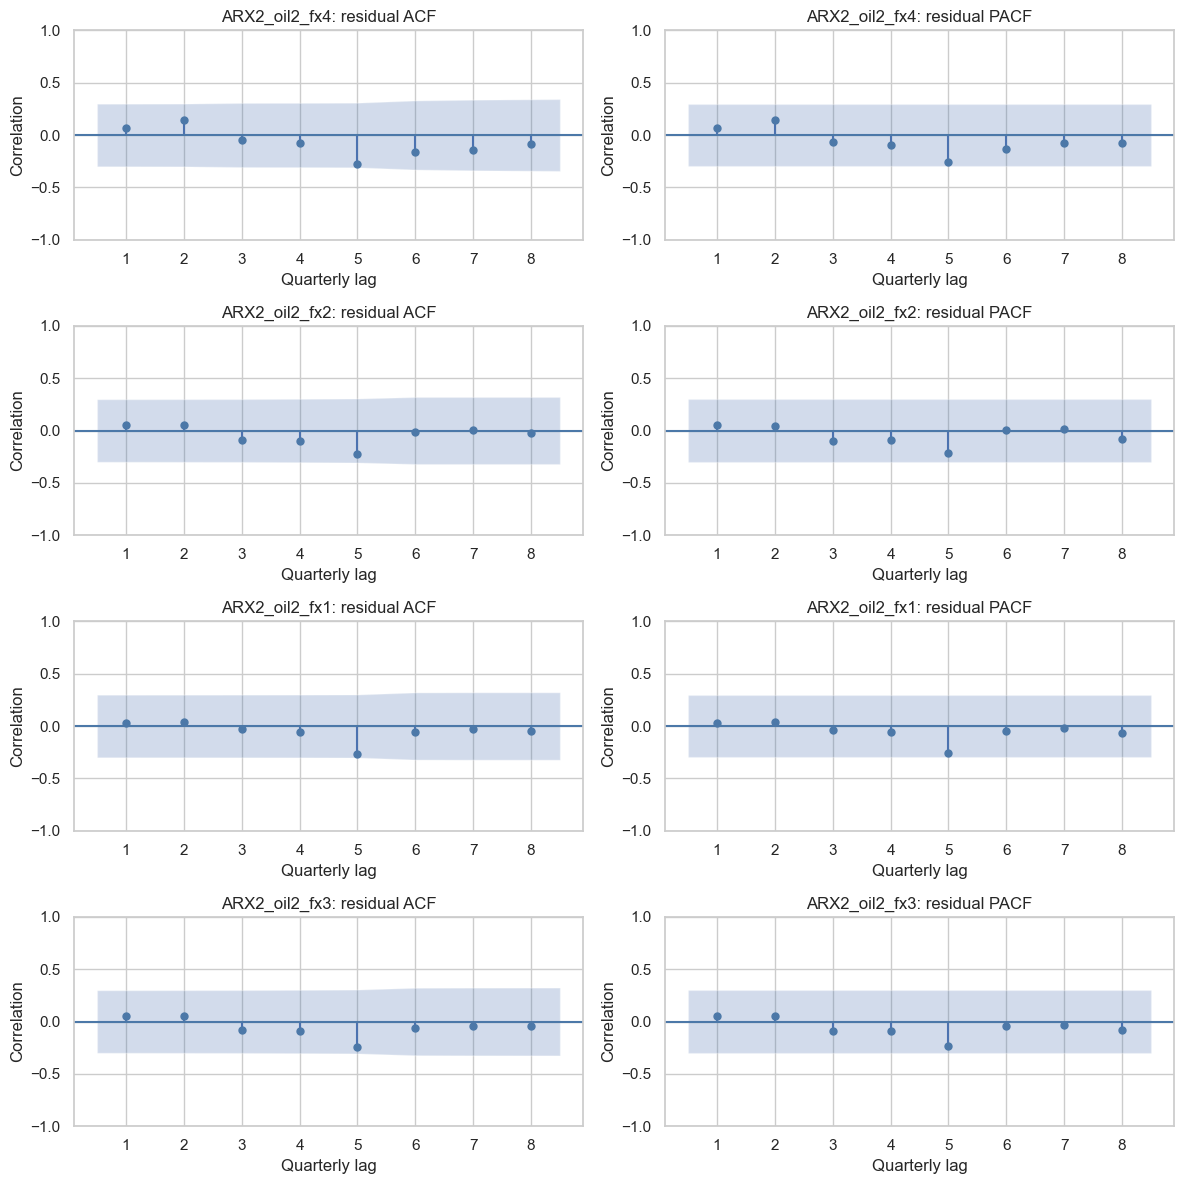

In [8]:
figure, axes = plt.subplots(
    len(shortlisted_models), 2,
    figsize=(12, 3 * len(shortlisted_models)),
    squeeze=False,
)

# visualize residual dependence only for the preliminary shortlist
for row_index, model_name in enumerate(shortlisted_models):
    residuals = arx_results[model_name].resid
    assert residuals.index.equals(model_data.index)
    assert np.isfinite(residuals.to_numpy()).all()
    assert RESIDUAL_PLOT_LAG < len(residuals) // 2
    plot_acf(
        residuals, lags=RESIDUAL_PLOT_LAG, zero=False, alpha=0.05,
        color="#4C78A8", ax=axes[row_index, 0],
        title=f"{model_name}: residual ACF",
    )
    plot_pacf(
        residuals, lags=RESIDUAL_PLOT_LAG, zero=False, alpha=0.05,
        method="ywm", color="#4C78A8", ax=axes[row_index, 1],
        title=f"{model_name}: residual PACF",
    )
    for axis in axes[row_index]:
        axis.set(xlabel="Quarterly lag", ylabel="Correlation")

figure.tight_layout()
plt.show()
plt.close(figure)

## Save candidate definitions

Export a training-only candidate manifest for the next stage. It records transformations, lag definitions, fit criteria and diagnostics; it does not lock a model or contain evaluation outcomes. Forecast validation and a separate final-test boundary remain to be specified.

In [9]:
candidate_manifest = {
    "status": "preliminary_training_shortlist_not_locked",
    "training_input": "data/processed/train.csv",
    "training_input_sha256": hashlib.sha256(TRAIN_DATA_PATH.read_bytes()).hexdigest(),
    "training_end": str(TRAIN_END),
    "model_sample_start": str(model_data.index.min()),
    "model_sample_end": str(model_data.index.max()),
    "model_observations": len(model_data),
    "target": TARGET_COLUMN,
    "transformations": {
        "npl": "first difference, percentage points",
        "brent": "100 times first difference of natural log",
        "usdkzt": "100 times first difference of natural log",
    },
    "npl_lags": NPL_LAGS,
    "macro_lag_candidates": MACRO_LAGS,
    "error_model": "no ma terms; conventional ols covariance",
    "parameter_count_includes_error_variance": True,
    "bg_test_lag": BG_TEST_LAG,
    "shortlist_delta_aicc": SHORTLIST_DELTA_AICC,
    "shortlisted_models": shortlisted_models,
    "candidate_specifications": candidate_specifications,
    "fit_comparison": json.loads(
        arx_fit_comparison.reset_index().to_json(orient="records")
    ),
    "diagnostics": json.loads(
        arx_diagnostics.reset_index().to_json(orient="records")
    ),
}

# save definitions and training diagnostics without modifying the input dataset
DIAGNOSTIC_DIRECTORY.mkdir(parents=True, exist_ok=True)
manifest_path = DIAGNOSTIC_DIRECTORY / "04_arx_candidate_manifest.json"
manifest_path.write_text(
    json.dumps(candidate_manifest, indent=2, allow_nan=False) + "\n",
    encoding="utf-8",
)
saved_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert saved_manifest == candidate_manifest
print(f"Saved candidate manifest: {manifest_path}")

Saved candidate manifest: ../reports/diagnostics/04_arx_candidate_manifest.json


## Conclusion

Fitted 16 ARX candidates on 43 pre-2022 target quarters, with NPL lags 1–2 and one lag each of oil and FX. Oil lag 2 appears in all four candidates within 2 AICc points of the best fit; the leading FX lag is 4, but FX-lag differences are small. Predictor VIFs are low and Breusch–Godfrey tests do not reject through lag 4. These are preliminary training results, not causal or forecasting evidence. Next, define chronological validation and final testing in Notebook 5 and compare the shortlist with NPL-only benchmarks and persistence.